# Four physical properties: logP, water solubility, boiling point and vapour pressure

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/31_physical_properties.ipynb)

The earlier notebooks model activities of congeneric series. This one models four physical
properties of diverse compounds, each with thousands of measured values:

- **logP**, the octanol-water partition coefficient;
- **logS**, the decimal logarithm of the water solubility in mol/L;
- the **normal boiling point**, in C;
- **logVP**, the decimal logarithm of the vapour pressure near 25 C, in mmHg.

Each property has a classic method that a chemist would use first: clogP, the ESOL equation of
Delaney, and the group contributions of Joback. The four benchmarks of the program set the
invariant field kernel against these and against several cheaper descriptions. One model is best
on all four properties: **the field kernel plus a Gaussian kernel on eight simple counts**.

The notebook asks three questions.

1. What does each description know, and how well does each one do alone?
2. The best model has a 3D part (the field kernel) and a part with no geometry (the counts). Is
   the 3D part needed, or would the same autocorrelation with distances counted in bonds do as
   well? This notebook measures that reference, which the benchmarks did not have.
3. What happens on compounds outside the range of the training set?

A small part runs live, on the Delaney solubility set. The rest reads the stored results of the
benchmarks, which take about four and a half hours together.

Running time: under a minute.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data

Each property has two sets, and the two sets of a property share no compound. Each compound has
one 3D structure (ETKDG, then MMFF94), stored in the repository.

- logP: the Huuskonen set and a sample of class P of SangsterLogP (values reported as logP by
  their authors).
- Solubility: the Delaney set and the compounds of AqSolDB measured more than once with a
  standard deviation below 0.5 log units.
- Boiling point and vapour pressure: the PHYSPROP values curated for the OPERA models, with the
  paper's training and test parts, and values from registration dossiers on eChemPortal that
  OPERA added later.

Each benchmark repeats five folds three times on each set. It also fits on one set and predicts
another that it has never seen (an external test). The cell lists the sets and the spread of
their values.

In [2]:
import json
import time

import numpy as np
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")
sys.path.insert(0, "benchmarks")
import run_logp as L                 # the fit, the kernels and the counts of the four benchmarks
import run_wavelet as RW             # the folds

start = time.time()
PROPS = ("logp", "solubility", "boiling", "vapour")
TITLE = {"logp": "logP", "solubility": "water solubility (logS)",
         "boiling": "boiling point (C)", "vapour": "vapour pressure (logVP)"}
bench = {}
for p in PROPS:
    with open(f"benchmarks/results/{p}/{p}.json", encoding="utf-8") as fh:
        bench[p] = json.load(fh)
with open("benchmarks/results/property_pairs/pairs.json", encoding="utf-8") as fh:
    pairs = json.load(fh)

for p in PROPS:
    print(TITLE[p])
    for part, n in bench[p]["compounds"].items():
        print("   %-18s %5d compounds, standard deviation %6.2f"
              % (part, n, bench[p]["y"][part]["sd"]))

logP
   huuskonen           1847 compounds, standard deviation   1.49
   sangster_p          2999 compounds, standard deviation   1.78
water solubility (logS)
   aqsoldb_reliable    1002 compounds, standard deviation   2.30
   delaney             1114 compounds, standard deviation   2.09
boiling point (C)
   echemportal         1617 compounds, standard deviation  85.60
   physprop_test       1353 compounds, standard deviation  83.94
   physprop_train      4059 compounds, standard deviation  85.32
vapour pressure (logVP)
   echemportal         2884 compounds, standard deviation   3.36
   physprop_test        677 compounds, standard deviation   3.55
   physprop_train      2016 compounds, standard deviation   3.55


## What each description knows

The models differ only in the kernel. All are kernel ridge regression with a bias, with the
settings and the ridge chosen by the evidence on each training block.

- **The classic reference.** For logP, a linear regression on clogP. For solubility, the ESOL
  equation: a linear regression on clogP, the molecular weight, the number of rotatable bonds and
  the aromatic proportion. For boiling point and vapour pressure, Joback's 41 groups. Each is
  refitted in every fold.
- **Eight counts.** A Gaussian kernel on eight numbers per molecule: the molecular weight, the
  numbers of hydrogen-bond donors, acceptors, rotatable bonds, rings and aromatic rings, the
  polar surface area and the fraction of sp3 carbons. They say how large, how polar and how
  flexible a molecule is.
- **The field kernel.** The invariant autocorrelation of the five classical fields
  (electrostatic, steric, hydrophobic, acceptor and donor): how much of each field lies at each
  distance from each other field. It needs a 3D structure but no alignment.
- **The topological kernel.** The same autocorrelation, with the distance between two atoms
  counted in bonds. It needs no 3D structure.

The hydrophobic field puts the Wildman-Crippen increments on the atoms, so its sum over a
molecule is exactly clogP. The cell checks that on the Delaney set and prints the eight counts of
three compounds.

In [3]:
from rdkit.Chem import Crippen
from cmfqsar.fields import FieldSet, build_fields

mols = [m for m in Chem.SDMolSupplier("examples/solubility/delaney.sdf", removeHs=False) if m]
y = np.array([float(m.GetProp("logS")) for m in mols])
heavy = [Chem.RemoveHs(m) for m in mols]
fs = FieldSet.create(physchem=L.FIELDS, alpha=1.0, charge_model="gasteiger", param_scheme="rdkit")
mfs = [build_fields(m, fs, m.GetProp("_Name")) for m in mols]
hydrophobic = np.array([mf.weights[:, L.FIELDS.index("hydrophobic")].sum() for mf in mfs])
clogp = np.array([Crippen.MolLogP(m) for m in heavy])
print("Delaney set: %d compounds; the hydrophobic field sum differs from clogP by at most %.1e"
      % (len(mols), np.max(np.abs(hydrophobic - clogp))))

from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors
COUNTS = ("weight", "donors", "acceptors", "rotatable", "rings", "aromatic rings", "polar area", "sp3 share")
print()
print("%-26s" % "compound" + "".join("%15s" % c for c in COUNTS))
for i in (0, 300, 700):
    m = heavy[i]
    row = (Descriptors.MolWt(m), Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m),
           rdMolDescriptors.CalcNumRotatableBonds(m), rdMolDescriptors.CalcNumRings(m),
           rdMolDescriptors.CalcNumAromaticRings(m), rdMolDescriptors.CalcTPSA(m),
           rdMolDescriptors.CalcFractionCSP3(m))
    print("%-26s" % mols[i].GetProp("_Name")[:25] + "".join("%15.2f" % v for v in row))

Delaney set: 1114 compounds; the hydrophobic field sum differs from clogP by at most 1.1e-14

compound                           weight         donors      acceptors      rotatable          rings aromatic rings     polar area      sp3 share
delaney-1                          457.43           7.00          12.00           7.00           3.00           1.00         202.32           0.65
delaney-301                         98.96           0.00           0.00           0.00           0.00           0.00           0.00           1.00
delaney-701                        116.20           1.00           1.00           3.00           0.00           0.00          20.23           1.00


## A live run on the Delaney set

The cell builds the four kernels for the 1,114 compounds of the Delaney set and runs one repeat
of five folds. To keep it short, it fixes the settings that the benchmark chose most often on this
set: a smoothing width of 0.05 A for the field kernel, a width of 0.5 for the Gaussian kernel on
the standardised counts, and all distances up to 40 bonds for the topological kernel. Only the
ridge, and for a sum the weight h of its second kernel, are chosen by the evidence on each
training block. The benchmark chooses every setting in every fold and repeats the folds three
times, so its numbers differ slightly.

In [4]:
from cmfqsar.invariant import AutocorrelationSpec, feature_matrix
from cmfqsar.model import r2_score

F = feature_matrix(mfs, AutocorrelationSpec(d_max=L.D_MAX, step=0.05, sigma=0.05), fieldset=fs)
K_field, _ = L.invariant_kernels(F, 0.05, len(fs.specs))
K_counts = L.gaussian_at(L.eight_counts(heavy), 0.5)
K_bonds = L.topological_kernel(L.topological_features(mols, mfs, 40), 40, len(fs.specs))


def q2(K_a, K_b=None):
    """q2 of one repeat of five folds; the ridge (and h for a sum) chosen by the evidence."""
    pred = np.zeros(len(y))
    for test in RW.folds(len(y), 5, 0):
        train = np.setdiff1d(np.arange(len(y)), test)
        best = None
        for h in (L.HS if K_b is not None else (0.0,)):
            K = K_a if K_b is None else K_a + h * K_b
            fit = L.Fit(K[np.ix_(train, train)], y[train])
            for lam in L.LAMS:
                ev = fit.evidence(lam)
                if best is None or ev > best[0]:
                    a, b = fit.coefficients(lam)
                    best = (ev, K[np.ix_(test, train)] @ a + b)
        pred[test] = best[1]
    return r2_score(y, pred)


stored = {"field kernel": ("invariant, cosine", bench), "eight counts": ("eight counts", bench),
          "topological kernel": ("topological autocorrelation", bench),
          "field kernel + eight counts": ("invariant + eight counts", bench),
          "topological kernel + eight counts": ("topological + eight counts", pairs)}
live = {"field kernel": q2(K_field), "eight counts": q2(K_counts),
        "topological kernel": q2(K_bonds),
        "field kernel + eight counts": q2(K_field, K_counts),
        "topological kernel + eight counts": q2(K_bonds, K_counts)}
print("%-36s %10s %12s" % ("model", "q2, live", "benchmark"))
for name, value in live.items():
    model, source = stored[name]
    print("%-36s %+10.3f %+12.3f" % (name, value, source["solubility"]["models"][model]["delaney"]["q2_mean"]))
print("(%.0f s so far)" % (time.time() - start))

model                                  q2, live    benchmark
field kernel                             +0.875       +0.875
eight counts                             +0.855       +0.853
topological kernel                       +0.850       +0.847
field kernel + eight counts              +0.905       +0.906
topological kernel + eight counts        +0.903       +0.902
(18 s so far)


**Each sum beats both of its parts, and the two sums are almost equal.** The field kernel alone
reaches q² 0.875 and the eight counts alone 0.855; their sum reaches 0.905. The topological
kernel alone reaches 0.850, and with the counts 0.903. On this set, then, a model that needs no
conformer comes within 0.002 of the best one.

The live numbers differ from the benchmark by 0.003 at most, although the cell fixed the settings
and ran one repeat of the folds. The next sections read the benchmark's numbers for all four
properties.

## All four properties

The cell prints the stored results of six models on every test: q² for cross-validation, R² for
an external test. *The topological kernel + eight counts* comes from
`benchmarks/run_property_pairs.py`, the reference added with this notebook. It uses the same
folds and the same selection rule as the benchmarks.

In [5]:
CLASSIC = {"logp": "linear regression on clogP", "solubility": "ESOL refitted",
           "boiling": "Joback refitted", "vapour": "Joback refitted"}
SHOWN = [("classic reference", None), ("eight counts", "eight counts"),
         ("topological kernel", "topological autocorrelation"), ("field kernel", "invariant, cosine"),
         ("topological kernel + counts", "topological + eight counts"),
         ("field kernel + counts", "invariant + eight counts")]


def score(p, model, test):
    source = pairs if model == "topological + eight counts" else bench
    r = source[p]["models"][model][test]
    return r["q2_mean"] if "q2_mean" in r else r["r2"]


for p in PROPS:
    tests = pairs[p]["tests"]
    titles = pairs[p]["titles"]
    print(TITLE[p], "(classic reference: %s)" % CLASSIC[p])
    print("   %-29s" % "model" + "".join("%15s" % t for t in range(1, len(tests) + 1)))
    for label, model in SHOWN:
        model = model or CLASSIC[p]
        print("   %-29s" % label + "".join("%+15.3f" % score(p, model, t) for t in tests))
    for k, t in enumerate(tests, 1):
        print("   test %d: %s" % (k, titles[t]))
    print()

logP (classic reference: linear regression on clogP)
   model                                      1              2              3
   classic reference                     +0.820         +0.710         +0.780
   eight counts                          +0.806         +0.672         +0.685
   topological kernel                    +0.871         +0.761         +0.782
   field kernel                          +0.884         +0.778         +0.803
   topological kernel + counts           +0.899         +0.804         +0.821
   field kernel + counts                 +0.906         +0.810         +0.841
   test 1: Huuskonen, CV
   test 2: class P, CV
   test 3: class P to Huuskonen

water solubility (logS) (classic reference: ESOL refitted)
   model                                      1              2              3
   classic reference                     +0.762         +0.784         +0.744
   eight counts                          +0.853         +0.832         +0.778
   topological kernel      

**Of these six models, the sum of the field kernel and the eight counts is the best on the clean
tests of all four properties.** The one exception is a tie: on the external solubility test the
sum with the topological kernel is 0.001 higher. The sums with Joback's groups in the benchmarks,
not shown here, equal it within 0.002 in cross-validation on PHYSPROP. It reaches q² 0.906 on
logP (Huuskonen set) and on solubility (Delaney set).
On the test parts of the OPERA paper it reaches R² 0.957 for boiling points and 0.921 for vapour
pressures; the paper reports 0.93 and 0.92 there.

**Every classic reference is beaten, but not always by the field kernel alone.** On vapour
pressure the refitted Joback groups (0.897 in cross-validation) and the eight counts (0.893, and
0.907 on the OPERA test) beat the field kernel alone (0.874 and 0.873). On the eChemPortal boiling
points the counts alone (0.517) beat it too (0.448). The field kernel and the counts know
different things, and their sum keeps both.

**The sum with the topological kernel comes second, and close.** On the eChemPortal boiling
points it is the best model (0.582 against 0.543), and on the external solubility test the two
sums are equal (0.868 and 0.867). The next section asks how large the difference between the two
sums is, and whether it is real.

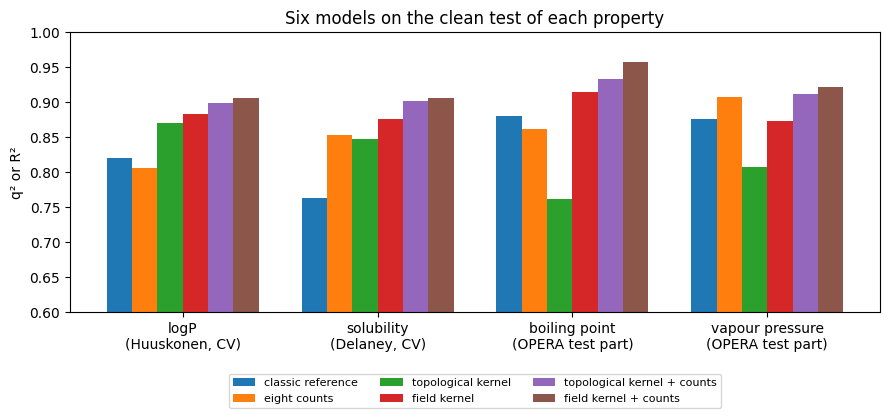

In [6]:
import matplotlib.pyplot as plt

clean = {"logp": "huuskonen", "solubility": "delaney", "boiling": "opera_test", "vapour": "opera_test"}
fig, ax = plt.subplots(figsize=(9, 4.4))
width = 0.13
for k, (label, model) in enumerate(SHOWN):
    values = [score(p, model or CLASSIC[p], clean[p]) for p in PROPS]
    ax.bar(np.arange(len(PROPS)) + (k - 2.5) * width, values, width, label=label)
ax.set_xticks(range(len(PROPS)))
ax.set_xticklabels(["logP\n(Huuskonen, CV)", "solubility\n(Delaney, CV)",
                    "boiling point\n(OPERA test part)", "vapour pressure\n(OPERA test part)"])
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("q² or R²")
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_title("Six models on the clean test of each property")
plt.tight_layout()
plt.show()

## What the 3D geometry adds

The field kernel and the topological kernel differ only in how a distance is measured: in
ångströms in one conformer, or in bonds. Their difference is what the 3D geometry adds. The cell
prints it twice for every test: for the two kernels alone (from the benchmarks), and with the
eight counts added to both (the new reference). Each difference carries a 95 % interval from a
paired bootstrap over the compounds.

In [7]:
def difference(source, model, against, test):
    for c in source["comparisons"]:
        if c["model"] == model and c["against"] == against and c["test"] == test:
            return c
    raise KeyError((model, against, test))


print("%-26s %-40s %24s %24s" % ("property", "test", "kernels alone", "with eight counts"))
for p in PROPS:
    for t in pairs[p]["tests"]:
        a = difference(bench[p], "invariant, cosine", "topological autocorrelation", t)
        b = difference(pairs[p], "invariant + eight counts", "topological + eight counts", t)
        print("%-26s %-40s %+7.3f [%+.3f, %+.3f] %+7.3f [%+.3f, %+.3f]"
              % (TITLE[p], pairs[p]["titles"][t], a["mean"], a["lo"], a["hi"],
                 b["mean"], b["lo"], b["hi"]))

property                   test                                                kernels alone        with eight counts
logP                       Huuskonen, CV                             +0.019 [+0.010, +0.027]  +0.010 [+0.004, +0.017]
logP                       class P, CV                               +0.022 [+0.013, +0.033]  +0.009 [+0.002, +0.017]
logP                       class P to Huuskonen                      +0.020 [+0.008, +0.034]  +0.020 [+0.010, +0.031]
water solubility (logS)    Delaney, CV                               +0.032 [+0.019, +0.045]  +0.006 [-0.001, +0.012]
water solubility (logS)    AqSolDB, CV                               +0.021 [+0.005, +0.037]  +0.011 [+0.001, +0.020]
water solubility (logS)    AqSolDB to Delaney                        +0.016 [+0.000, +0.031]  -0.001 [-0.009, +0.009]
boiling point (C)          PHYSPROP training part, CV                +0.161 [+0.146, +0.176]  +0.018 [+0.014, +0.022]
boiling point (C)          eChemPortal, CV              

**Alone, the field kernel is clearly ahead of the topological kernel.** The lead is 0.016 to
0.032 on logP and solubility, 0.06 to 0.09 on vapour pressure, and 0.15 to 0.16 on the PHYSPROP boiling
points (+0.161 [+0.146, +0.176] in cross-validation).

**With the eight counts added to both, most of that lead is gone.** On the clean tests it is now
0.009 to 0.020 on logP, 0.008 to 0.010 on vapour pressure (PHYSPROP) and 0.018 to 0.024 on
boiling points, and it is about zero on solubility. On the PHYSPROP boiling points it falls from
0.161 to 0.018. So the counts give the topological kernel most of what it lacked. A likely reason
is the size of the molecule: the cosine normalisation of both kernels divides it out, and the
first of the eight counts is the molecular weight.

**What is left is small, but mostly real.** Of the 14 intervals with the counts added, 10 lie above
zero, three include zero (the Delaney set, the external solubility test and the eChemPortal vapour
pressures), and one lies below zero (the eChemPortal boiling points, -0.028).

**The 3D geometry matters more when a model extrapolates.** From the PHYSPROP training part to
the eChemPortal compounds, the field kernel plus the counts is ahead by +0.142 [+0.096, +0.194] on
boiling points and by +0.058 [+0.036, +0.079] on vapour pressures. The next section looks at this
test more closely.

## Compounds outside the range of the training set

The eChemPortal compounds are not a random sample of the same population. Their boiling points
are about 70 C higher than those of PHYSPROP, for example. The last test of the boiling point and
vapour pressure benchmarks fits on the PHYSPROP training part and predicts the eChemPortal set.
The cell compares the models there, together with the published Joback equation for boiling
points, which uses its own increments and no fitting.

In [8]:
EXTRA = SHOWN + [("refitted Crippen increments", "refitted Crippen increments")]
for p in ("boiling", "vapour"):
    print(TITLE[p], "- PHYSPROP training part to eChemPortal (R²)")
    for label, model in EXTRA:
        model = model or CLASSIC[p]
        print("   %-30s %+7.3f" % (label, score(p, model, "to_echemportal")))
    if "published_joback" in bench[p]:
        r = bench[p]["published_joback"]["echemportal"]
        print("   %-30s %+7.3f  (on %d of %d compounds that its groups cover)"
              % ("published Joback equation", r["r2"], r["covered"], r["of"]))
    print()
print("(%.0f s in all)" % (time.time() - start))

boiling point (C) - PHYSPROP training part to eChemPortal (R²)
   classic reference               -0.963
   eight counts                    +0.534
   topological kernel              +0.258
   field kernel                    +0.291
   topological kernel + counts     +0.427
   field kernel + counts           +0.569
   refitted Crippen increments     -0.970
   published Joback equation       -2.683  (on 1324 of 1617 compounds that its groups cover)

vapour pressure (logVP) - PHYSPROP training part to eChemPortal (R²)
   classic reference               -0.367
   eight counts                    +0.477
   topological kernel              +0.209
   field kernel                    +0.276
   topological kernel + counts     +0.383
   field kernel + counts           +0.441
   refitted Crippen increments     -0.387

(18 s in all)


**Models built from refitted increments fail here.** The refitted Joback groups reach R² -0.963 on
the boiling points and -0.367 on the vapour pressures: they predict worse than the mean of the
eChemPortal values. The refitted Crippen increments fail in the same way, and the published Joback
equation reaches -2.683. A sum of increments grows without limit with the size of a molecule, and
the eChemPortal compounds lie outside the range of the training compounds: their boiling points
are about 70 C higher, for example.

**Gaussian kernels on a few numbers do not fail.** Far from the training compounds, such a kernel
falls back towards the mean of the training values. The eight counts alone reach 0.534 and 0.477.
On boiling points the field kernel plus the counts is the best model (0.569). On vapour pressures
the counts alone are better than every sum (0.477 against 0.441 for the field kernel plus the
counts). Without a conformer, the sum with the topological kernel reaches 0.427 and 0.383.

All models stay near q² 0.5 in cross-validation on the eChemPortal sets, so much of their spread
is not explained by any of these structures. The manual notes a possible reason for the vapour
pressures: 236 of the eChemPortal values are a whole power of ten in pascals. In a registration
dossier such a value is often a limit ("below 0.001 Pa") rather than a measurement.

## What to take from this notebook

- For logP, solubility, boiling point and vapour pressure, the field kernel plus a Gaussian kernel
  on eight counts is the best of these models on the clean tests, or ties with the best. It beats clogP, ESOL and Joback's groups,
  and it matches or beats the OPERA models on their own test parts.
- The field kernel and the counts know different things. Each beats the other on some property,
  and their sum keeps the strengths of both.
- Measure what the 3D geometry adds against the same autocorrelation with distances in bonds,
  and with the same counts added to both. Alone, the field kernel led by up to 0.16. With the
  counts it leads by 0.00 to 0.02 on clean data.
- Without a conformer, the topological kernel plus the counts comes within 0.025 of the best
  model on clean data. A conformer adds more when a model extrapolates (+0.14 on boiling points).
- Refitted increments extrapolate badly to larger compounds. A Gaussian kernel on a few counts is
  the safer model there.

The reference added with this notebook is `benchmarks/run_property_pairs.py`. It reads the
predictions that the four benchmarks leave in `benchmarks/cache`, so run them first:

```
python benchmarks/run_logp.py
python benchmarks/run_solubility.py
python benchmarks/run_boiling.py
python benchmarks/run_vapour.py
python benchmarks/run_property_pairs.py
```

The four benchmarks take about four and a half hours together, and the last command about 70
minutes. It writes `benchmarks/results/property_pairs/table.md`.

The command line builds the field kernel with `cmf build --kernel autocorrelation`. It does not
offer the topological kernel or the Gaussian kernel on the eight counts. They are in
`benchmarks/run_logp.py` (`topological_features`, `topological_kernel`, `eight_counts`,
`gaussian_at`).

Where to read further in the manual: *Four physical properties of molecules: logP, water
solubility, boiling point and vapour pressure* has all four benchmarks and this reference; *The
rotation-invariant autocorrelation kernel* has the kernel itself.